# Importing dependencies

In [25]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import precision_score, recall_score,f1_score,confusion_matrix

# Importing the data

In [2]:
df = pd.read_csv("../DataSets/loan_approval_data.csv")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    object 
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    object 
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    object 
 15  Property_Area       950 non-null    object 
 16  Educati

# Quick analysis of the data

In [3]:
df.isnull().sum()
df.sample(5)

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
760,761.0,16594.0,1300.0,Contract,47.0,Married,3.0,675.0,3.0,0.29,493.0,4295.0,12183.0,36.0,Personal,Urban,Graduate,Male,Government,Yes
965,966.0,5054.0,6928.0,Contract,38.0,Single,1.0,621.0,4.0,0.30,17753.0,557.0,33813.0,72.0,Personal,Semiurban,Not Graduate,Male,Private,No
894,895.0,15224.0,5435.0,NaN,54.0,Married,3.0,560.0,4.0,0.52,18738.0,14551.0,31614.0,12.0,Business,Semiurban,Graduate,Male,Private,No
311,312.0,4491.0,NaN,Salaried,NaN,NaN,2.0,565.0,0.0,0.31,19159.0,38362.0,21754.0,72.0,Education,Urban,Graduate,Male,Private,No
477,478.0,5141.0,8442.0,Contract,31.0,NaN,0.0,611.0,0.0,0.35,NaN,13454.0,36399.0,36.0,Education,Urban,Graduate,Female,Private,No


# Handling missing values

In [4]:
#Separate categorical and missing values
categ_cols = df.select_dtypes(include=['object']).columns
num_cols = df.select_dtypes(include=['number']).columns #Number refers to all types of float and int numbers


#Using simple imputer to fill the missing values
num_imp = SimpleImputer(strategy='mean')
df[num_cols] = num_imp.fit_transform(df[num_cols])

categ_imp = SimpleImputer(strategy='most_frequent')
df[categ_cols] = categ_imp.fit_transform(df[categ_cols])

df.isnull().sum()


Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA

Loan_Approved
No     702
Yes    298
Name: count, dtype: int64


[]

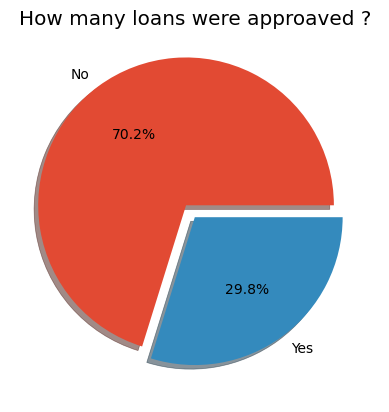

In [5]:
loan_approaved_cnt = df['Loan_Approved'].value_counts()
print(loan_approaved_cnt)
plt.style.use("ggplot")
plt.pie(loan_approaved_cnt, labels=['No','Yes'], autopct='%1.1f%%',shadow=True,explode=[0.1,0])
plt.title("How many loans were approaved ?")
plt.plot()
# Insight : - Only 30% of total loans were approaved

Gender
Male      621
Female    379
Name: count, dtype: int64


[]

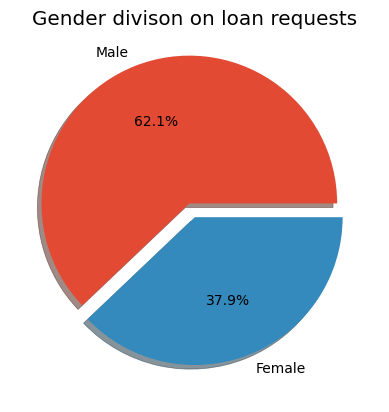

In [6]:
# prop_area_cnt = df['Property_Area'].value_counts()
# print(prop_area_cnt)
# plt.pie(prop_area_cnt, labels=['Urban','Rural', 'Semiurban'], autopct='%1.1f%%',shadow=True,explode=[0.1,0,0])
# plt.title("From where were the loans taken?")
# plt.plot()
#Insight : - 50% of applicants come from Rural area

gender_cnt = df['Gender'].value_counts()
print(gender_cnt)
plt.pie(gender_cnt, labels=['Male','Female'], autopct='%1.1f%%',shadow=True,explode=[0.1,0])
plt.title("Gender divison on loan requests")
plt.plot()
#Insight : - Majority(62%) of the applicants are Male

Text(0.5, 1.0, 'Credit Score Distribution by Loan Approval')

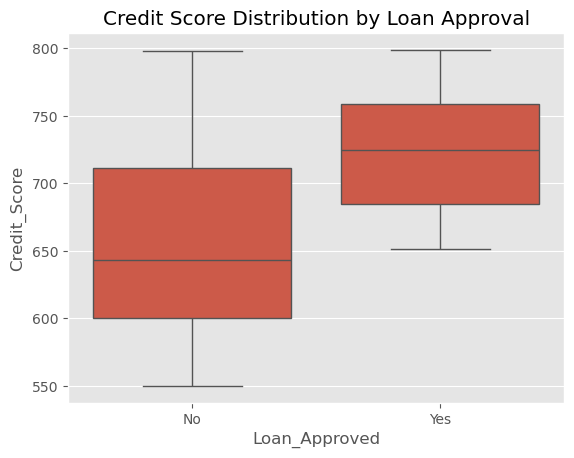

In [7]:
sns.boxplot(
    data=df,
    x='Loan_Approved',
    y='Credit_Score'
)
plt.title('Credit Score Distribution by Loan Approval')
#Insight : - In approved loans, the majority of the applicants have a credit score in the range 700 to 750 and minimum most credit score to get a loan is 650

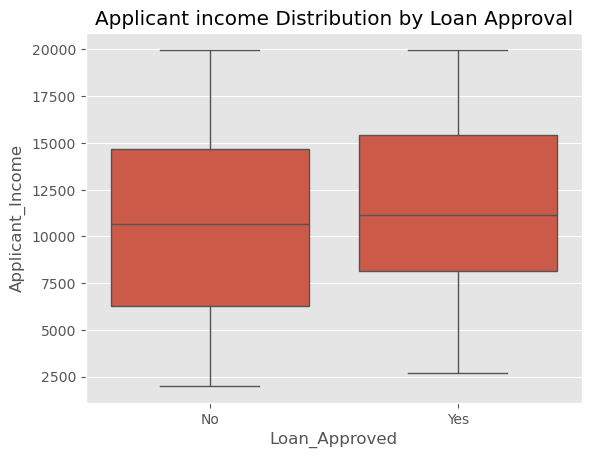

In [8]:
sns.boxplot(
    data=df,
    x='Loan_Approved',
    y='Applicant_Income'
)
plt.title('Applicant income Distribution by Loan Approval')
plt.show()
#Insight : - The incomes to get approval of loans are quite similar to the not-approaved ones , so income is not that big issue here. Still to say, approved income range(avg) : 8000 to 15000

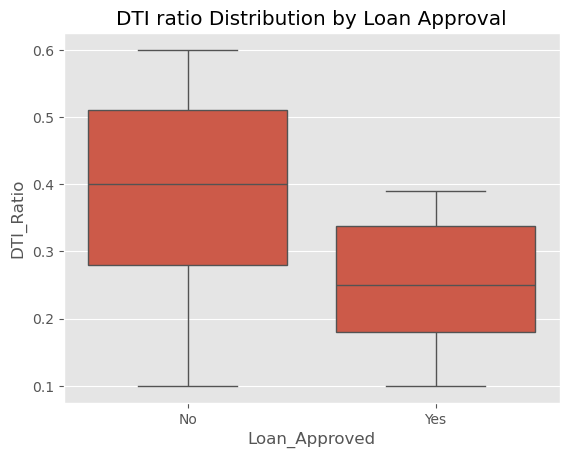

In [9]:
sns.boxplot(
    data=df,
    x='Loan_Approved',
    y='DTI_Ratio'
)
plt.title('DTI ratio Distribution by Loan Approval')
plt.show()
#Insight :- Approved loans has a lower DTI ratio ( on average 0.2 to 0.35 ) than not-approved ones and the maximum DTI for approved loans is 0.4

<Axes: xlabel='Applicant_Income', ylabel='Count'>

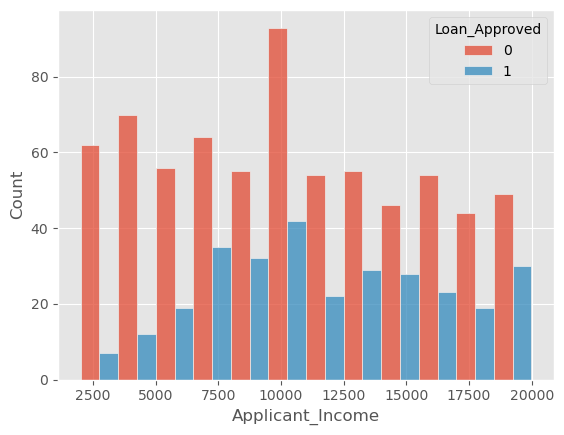

In [29]:
sns.histplot(data = df, x = 'Applicant_Income' , hue = 'Loan_Approved',multiple='dodge')

In [10]:
# Drop the applicant id 

df = df.drop(columns=["Applicant_ID"])
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


# Encoding

In [11]:
# Sorting out the nominal cols
nom_cols = ["Employment_Status","Marital_Status","Loan_Purpose","Property_Area","Gender","Employer_Category"]


#OneHotencoder
oe = OneHotEncoder(drop="first", sparse_output=False,handle_unknown='ignore')
encoded_noms = oe.fit_transform(df[nom_cols])
encoded_df = pd.DataFrame(encoded_noms , columns = oe.get_feature_names_out(nom_cols),index = df.index)
df = pd.concat([df.drop(columns=nom_cols) , encoded_df],axis=1)

In [12]:
#LabelEncoder

le = LabelEncoder()
df["Education_Level"] = le.fit_transform(df["Education_Level"])
df["Loan_Approved"] = le.fit_transform(df["Loan_Approved"])
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 28 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Applicant_Income                 1000 non-null   float64
 1   Coapplicant_Income               1000 non-null   float64
 2   Age                              1000 non-null   float64
 3   Dependents                       1000 non-null   float64
 4   Credit_Score                     1000 non-null   float64
 5   Existing_Loans                   1000 non-null   float64
 6   DTI_Ratio                        1000 non-null   float64
 7   Savings                          1000 non-null   float64
 8   Collateral_Value                 1000 non-null   float64
 9   Loan_Amount                      1000 non-null   float64
 10  Loan_Term                        1000 non-null   float64
 11  Education_Level                  1000 non-null   int64  
 12  Loan_Approved        

# Correlation Heatmap

In [ ]:
corr_mat = df.corr()
plt.figure(figsize=(20, 10))
sns.heatmap(
    corr_mat,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.tight_layout()

# Feature scaling & Train-test split

In [16]:
# Divide into X and y 
X = df.drop(columns = ['Loan_Approved'])
y = df['Loan_Approved']


#Train-test-split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



#Scaling 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model training & Evaluation 

In [22]:
# Logistic regression
logreg = LogisticRegression()
logreg.fit(X_train_scaled,y_train)
y_pred = logreg.predict(X_test_scaled)

print("Precision score : ",precision_score(y_test,y_pred))
print("Recall score : ",recall_score(y_test,y_pred))
print("F1 score : ",f1_score(y_test,y_pred))

Precision score :  0.7833333333333333
Recall score :  0.7704918032786885
F1 score :  0.7768595041322314


In [24]:
#KNN 
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled,y_train)
y_pred = knn.predict(X_test_scaled)

print("Precision score : ",precision_score(y_test,y_pred))
print("Recall score : ",recall_score(y_test,y_pred))
print("F1 score : ",f1_score(y_test,y_pred))

Precision score :  0.6274509803921569
Recall score :  0.5245901639344263
F1 score :  0.5714285714285714


In [26]:
#Naive Bayes Gaussian
nb = GaussianNB()
nb.fit(X_train_scaled,y_train)
y_pred = nb.predict(X_test_scaled)

print("Precision score : ",precision_score(y_test,y_pred))
print("Recall score : ",recall_score(y_test,y_pred))
print("F1 score : ",f1_score(y_test,y_pred))

Precision score :  0.8035714285714286
Recall score :  0.7377049180327869
F1 score :  0.7692307692307693


# Feature Engineering

In [30]:
#Squaring DTI Ratio and Credit Score
df['DTI_Ratio_sq'] = df['DTI_Ratio'] **2
df['Credit_Score_sq'] = df['Credit_Score'] **2

# Divide into X and y 
X = df.drop(columns = ['Loan_Approved','Credit_Score','DTI_Ratio'])
y = df['Loan_Approved']


#Train-test-split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

#Scaling 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [31]:
# Logistic regression
logreg = LogisticRegression()
logreg.fit(X_train_scaled,y_train)
y_pred = logreg.predict(X_test_scaled)

print("Precision score : ",precision_score(y_test,y_pred))
print("Recall score : ",recall_score(y_test,y_pred))
print("F1 score : ",f1_score(y_test,y_pred))

Precision score :  0.7903225806451613
Recall score :  0.8032786885245902
F1 score :  0.7967479674796748


In [32]:
#Naive Bayes Gaussian
nb = GaussianNB()
nb.fit(X_train_scaled,y_train)
y_pred = nb.predict(X_test_scaled)

print("Precision score : ",precision_score(y_test,y_pred))
print("Recall score : ",recall_score(y_test,y_pred))
print("F1 score : ",f1_score(y_test,y_pred))

Precision score :  0.7833333333333333
Recall score :  0.7704918032786885
F1 score :  0.7768595041322314
